<a href="https://colab.research.google.com/github/kumarmaheshbly-oss/Project-Aura-/blob/main/aura_shield_v11_smooth_orbits.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install skyfield numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [skyfield]


🛰️ AURA-SHIELD v11.0 (REAL DATA ENGINE)
Minimum Distance: 5856.92 km
Probability (Pc): 0.00e+00


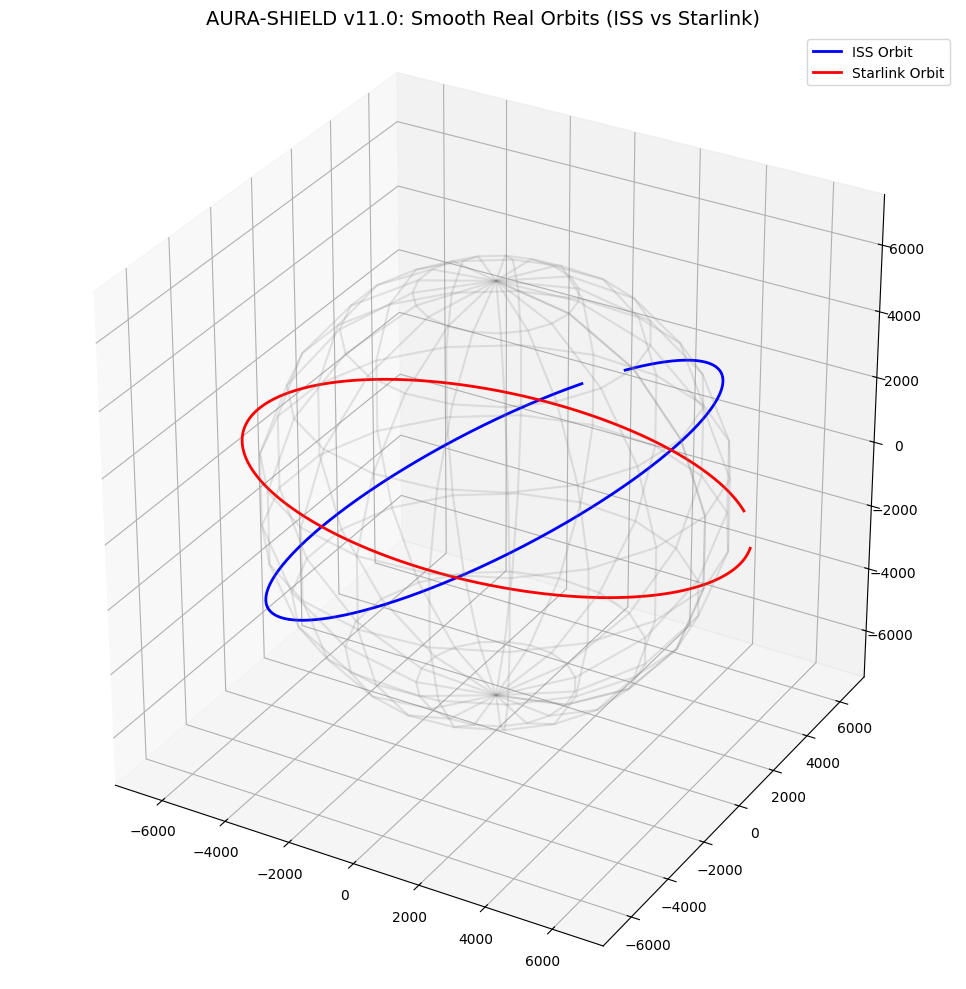

In [5]:

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from skyfield.api import EarthSatellite, load

# 1. Setup Time (Sirf 90 minute, lekin har 10 second ka data - Smooth curve ke liye)
ts = load.timescale()
# range(0, 5400, 10) ka matlab: 0 se 5400 seconds (90 mins) tak, har 10 second par data
t = ts.utc(2024, 5, 1, 0, 0, range(0, 5400, 10))

# 2. REAL TLE DATA
iss_tle = [
    '1 25544U 98067A   24121.54791667  .00016717  00000+0  30777-3 0  9993',
    '2 25544  51.6416 247.4627 0006703 130.5360 325.0288 15.49815570444578'
]
starlink_tle = [
    '1 44713U 19074A   24121.50000000  .00002182  00000+0  16411-3 0  9990',
    '2 44713  53.0541 198.3234 0001421  93.8295 266.2878 15.06384507244455'
]

# 3. Satellites Load Karein
iss = EarthSatellite(iss_tle[0], iss_tle[1], 'ISS (ZARYA)', ts)
starlink = EarthSatellite(starlink_tle[0], starlink_tle[1], 'STARLINK-1007', ts)

# 4. Real 3D Positions
pos_iss = iss.at(t).position.km
pos_sl = starlink.at(t).position.km

# 5. Distance aur Pc Calculation
distances = np.linalg.norm(pos_iss - pos_sl, axis=0)
min_dist = np.min(distances)

sigma = 0.5
hbr = 0.02
pc = (hbr**2 / (2 * np.pi * sigma**2)) * np.exp(-(min_dist**2) / (2 * sigma**2)) if min_dist < 50.0 else 0.0

print("="*60)
print(f"🛰️ AURA-SHIELD v11.0 (REAL DATA ENGINE)")
print("="*60)
print(f"Minimum Distance: {min_dist:.2f} km")
print(f"Probability (Pc): {pc:.2e}")

# 6. The PERFECT Smooth 3D Graph
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

# Earth Wireframe
u, v = np.mgrid[0:2*np.pi:20j, 0:np.pi:10j]
xe = 6371 * np.cos(u)*np.sin(v)
ye = 6371 * np.sin(u)*np.sin(v)
ze = 6371 * np.cos(v)
ax.plot_wireframe(xe, ye, ze, color='gray', alpha=0.2)

# Plot Orbits (Ab ye smooth curve banenge)
ax.plot(pos_iss[0], pos_iss[1], pos_iss[2], color='blue', label='ISS Orbit', linewidth=2)
ax.plot(pos_sl[0], pos_sl[1], pos_sl[2], color='red', label='Starlink Orbit', linewidth=2)

max_val = 7500
ax.set_xlim([-max_val, max_val])
ax.set_ylim([-max_val, max_val])
ax.set_zlim([-max_val, max_val])
ax.set_box_aspect([1, 1, 1])

ax.set_title('AURA-SHIELD v11.0: Smooth Real Orbits (ISS vs Starlink)', fontsize=14)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()